In [1]:
## Setup
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, confusion_matrix, precision_score,
                             recall_score, f1_score, classification_report)
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Create synthetic imbalanced data
np.random.seed(42)
n_samples = 1000
fraud_rate = 0.02

# Features (e.g., transaction amount and distance from home)
X = np.random.randn(n_samples, 2)
# Target (0 = Normal, 1 = Fraud)
y = np.zeros(n_samples)
y[:int(n_samples * fraud_rate)] = 1
np.random.shuffle(y)

In [3]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

print(f"Total Transactions: {len(y)}")
print(f"Fraudulent cases: {int(sum(y))}")
print(f"Normal cases: {int(len(y) - sum(y))}")

Total Transactions: 1000
Fraudulent cases: 20
Normal cases: 980


In [4]:
# A model that always predicts 'Normal' (0)
dummy_predictions = np.zeros(len(y_test))

print(f"Dummy Model Accuracy: {accuracy_score(y_test, dummy_predictions):.2%}")

Dummy Model Accuracy: 99.33%


In [5]:
# Now, let's train a classification model and see how it actually performs

model = LogisticRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_probs = model.predict_proba(X_test)[:, 1]

print(f"Model Accuracy: {accuracy_score(y_test, y_pred):.2%}")


Model Accuracy: 99.33%


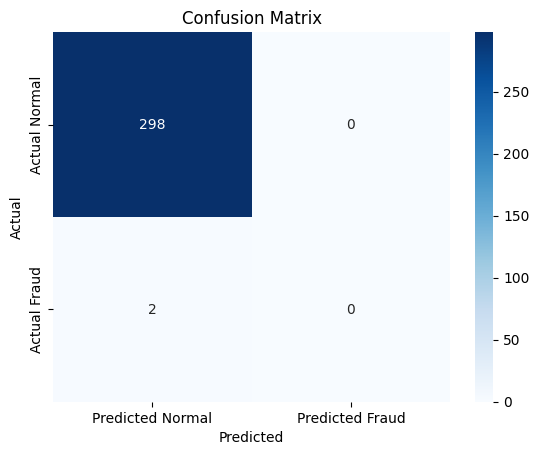

In [6]:
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted Normal', 'Predicted Fraud'],
            yticklabels=['Actual Normal', 'Actual Fraud'])
plt.ylabel('Actual')
plt.xlabel('Predicted')
plt.title('Confusion Matrix')
plt.show()

In [7]:
print(f"Precision: {precision_score(y_test, y_pred):.2f}")
print(f"Recall: {recall_score(y_test, y_pred):.2f}")
print(f"F1-Score: {f1_score(y_test, y_pred):.2f}")

Precision: 0.00
Recall: 0.00
F1-Score: 0.00


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [10]:
# Lowering the threshold to 0.2 (20%) to catch more fraud
new_threshold = 0.1
y_pred_new = (y_probs >= new_threshold).astype(int)

print(f"--- Results with {new_threshold*100}% Threshold ---")
print(f"New Recall: {recall_score(y_test, y_pred_new):.2f}")
print(f"New Precision: {precision_score(y_test, y_pred_new):.2f}")

--- Results with 10.0% Threshold ---
New Recall: 0.00
New Precision: 0.00


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 due to no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [9]:
print(classification_report(y_test, y_pred, target_names=['Normal', 'Fraud']))

              precision    recall  f1-score   support

      Normal       0.99      1.00      1.00       298
       Fraud       0.00      0.00      0.00         2

    accuracy                           0.99       300
   macro avg       0.50      0.50      0.50       300
weighted avg       0.99      0.99      0.99       300



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
